In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pixell import enmap
import pandas as pd
import os

In [ ]:
y_ = np.load("../dataset/logM500c.npy")
y_ = np.load("../dataset/logM500cUncorr.npy")

In [3]:
dir_path = '../data processing/'
df = pd.read_csv(dir_path + "clusters_selected.csv")

In [5]:
import numpy as np
from sklearn.model_selection import train_test_split

def proportional_split_indices(y, test_size=0.2, n_quantiles=10, random_state=None):
    """
    Делит индексы train/test, сохраняя общее распределение y,
    даже если классы слишком редкие (без строгой стратификации).
    """
    y = np.asarray(y)
    rng = np.random.default_rng(random_state)
    n = len(y)

    # Разбиваем по квантилям
    quantiles = np.quantile(y, np.linspace(0, 1, n_quantiles + 1))
    y_strata = np.digitize(y, quantiles, right=True)

    train_idx = []
    test_idx = []

    for q in np.unique(y_strata):
        idxs = np.where(y_strata == q)[0]
        if len(idxs) < 2:
            train_idx.extend(idxs)
            continue
        n_test = max(1, int(len(idxs) * test_size))
        test_sel = rng.choice(idxs, size=n_test, replace=False)
        train_sel = np.setdiff1d(idxs, test_sel)
        train_idx.extend(train_sel)
        test_idx.extend(test_sel)

    return np.array(train_idx), np.array(test_idx)

In [20]:
train_idx, test_idx = proportional_split_indices(y, test_size=0.2, n_quantiles=2, random_state=42)

print("Размер train:", len(train_idx))
print("Размер test:", len(test_idx))
print("Пример диапазонов:")
print("Train min/max:", y[train_idx].min(), y[train_idx].max())
print("Test min/max:", y[test_idx].min(), y[test_idx].max())

Размер train: 7983
Размер test: 1994
Пример диапазонов:
Train min/max: 0.1980198 1.5085509
Test min/max: 0.25082508 1.4542454


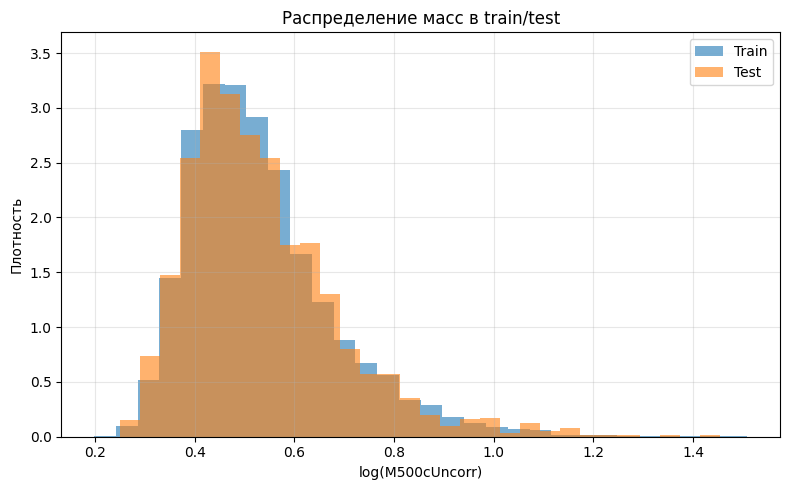

In [22]:
plt.figure(figsize=(8, 5))
plt.hist(y[train_idx], bins=30, alpha=0.6, label="Train", color="tab:blue", density=True)
plt.hist(y[test_idx], bins=30, alpha=0.6, label="Test", color="tab:orange", density=True)
plt.xlabel("log(M500cUncorr)")
plt.ylabel("Плотность")
plt.title("Распределение масс в train/test")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

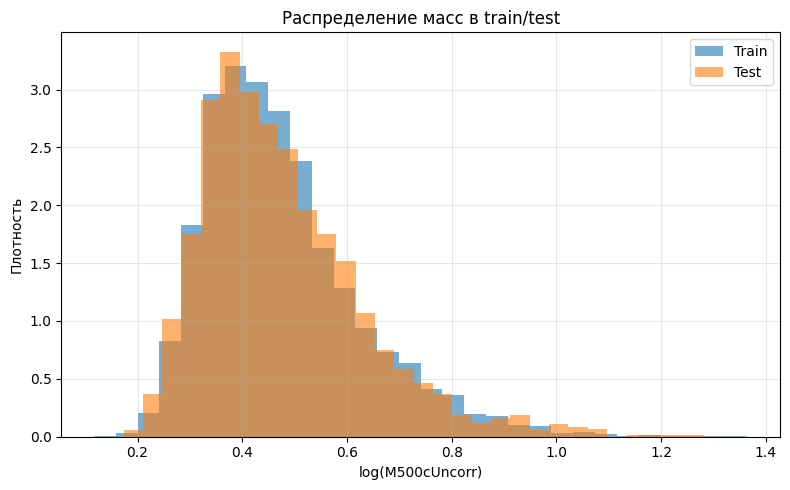

In [23]:
plt.figure(figsize=(8, 5))
plt.hist(y_[train_idx], bins=30, alpha=0.6, label="Train", color="tab:blue", density=True)
plt.hist(y_[test_idx], bins=30, alpha=0.6, label="Test", color="tab:orange", density=True)
plt.xlabel("log(M500c)")
plt.ylabel("Плотность")
plt.title("Распределение масс в train/test")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
np.save("data/base/train_indices.npy", train_idx)
np.save("data/base/test_indices.npy", test_idx)

In [25]:
np.save("data/norm/train_indices.npy", train_idx)
np.save("data/norm/test_indices.npy", test_idx)

In [12]:
y_augm = np.load("../dataset/logM500cUncorr_augm.npy")

In [13]:
y_augm.shape

(14474,)

In [14]:
train_idx, test_idx = proportional_split_indices(y_augm, test_size=0.2, n_quantiles=2, random_state=42)

print("Размер train:", len(train_idx))
print("Размер test:", len(test_idx))
print("Пример диапазонов:")
print("Train min/max:", y_augm[train_idx].min(), y_augm[train_idx].max())
print("Test min/max:", y_augm[test_idx].min(), y_augm[test_idx].max())

Размер train: 11580
Размер test: 2894
Пример диапазонов:
Train min/max: 0.1980198 1.5085509
Test min/max: 0.23162316 1.4542454


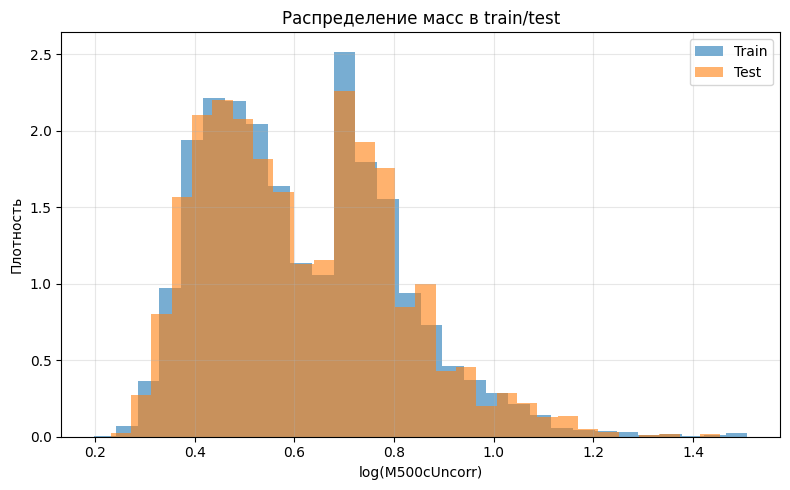

In [15]:
plt.figure(figsize=(8, 5))
plt.hist(y_augm[train_idx], bins=30, alpha=0.6, label="Train", color="tab:blue", density=True)
plt.hist(y_augm[test_idx], bins=30, alpha=0.6, label="Test", color="tab:orange", density=True)
plt.xlabel("log(M500cUncorr)")
plt.ylabel("Плотность")
plt.title("Распределение масс в train/test")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
np.save("data/augm_norm/train_indices.npy", train_idx)
np.save("data/augm_norm/test_indices.npy", test_idx)